<a href="https://colab.research.google.com/github/mahavirsariyam-png/LULC-analysis-Using-LISS-IV-data-/blob/main/LULC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install opencv-python tqdm matplotlib

In [ ]:
import os
import json
import numpy as np
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt

In [ ]:
IMAGE_DIR =  "/content/drive/MyDrive/LULC_Project/LULC train"
JSON_PATH =  "/content/drive/MyDrive/LULC_Project/LULC_meghalaya.json"
MASK_DIR =  "/content/drive/MyDrive/LULC_Project/masks"

os.makedirs(MASK_DIR, exist_ok=True)

In [ ]:
def normalize_label(label):
    label = label.lower().strip()
    label = label.replace(" / ", "/")
    label = label.replace("/ ", "/")
    label = label.replace(" /", "/")
    label = " ".join(label.split())
    return label

In [ ]:
ALIAS_MAP = {

    # AGRICULTURE
    "crop land": "cropland",
    "cropland": "cropland",
    "fallow": "fallow",
    "plantation": "plantation",

    # BARREN
    "sandy area": "sandy",
    "scrub land": "scrub",

    # BUILT
    "mining": "mining",
    "rural": "rural",
    "urban": "urban",

    # FOREST
    "deciduous": "deciduous",
    "decidious": "deciduous",

    "evergreen": "evergreen",
    "evergreen/semi-evergreen": "evergreen",
    "evergreen/semi-green": "evergreen",
    "evergren/semi-evergreen": "evergreen",

    "forest plantation": "forest_plantation",

    # GRASS
    "grass/grazing": "grass",
    "grass": "grass",

    # WATER
    "inland wetland": "wetland",

    "river/stream/canals": "river",
    "river/stream": "river",
    "river/stream/canal": "river",

    "water bodies": "water",
}

In [ ]:
CLASS_MAP = {
    # Agriculture
    "cropland": 1,
    "fallow": 1,
    "plantation": 1,

    # Barren
    "sandy": 2,
    "scrub": 2,

    # Built
    "mining": 3,
    "rural": 3,
    "urban": 3,

    # Forest
    "deciduous": 4,
    "evergreen": 4,
    "forest_plantation": 4,

    # Grass
    "grass": 5,

    # Water
    "wetland": 6,
    "river": 6,
    "water": 6,
}

In [ ]:
with open(JSON_PATH) as f:
    data = json.load(f)

unknown_labels = set()

for key in tqdm(data.keys()):
    item = data[key]
    filename = item['filename']

    image_path = os.path.join(IMAGE_DIR, filename)
    image = cv2.imread(image_path)

    if image is None:
        print("Missing image:", filename)
        continue

    h, w, _ = image.shape
    mask = np.zeros((h, w), dtype=np.uint8)

    for region in item['regions']:
        shape = region['shape_attributes']
        attrs = region['region_attributes']

        if len(attrs) == 0:
            continue


        l1 = list(attrs.keys())[0]
        l2 = list(attrs.values())[0]

        label = normalize_label(l2)

        if label not in ALIAS_MAP:
            unknown_labels.add(label)
            continue

        label = ALIAS_MAP[label]
        class_id = CLASS_MAP[label]

        x = shape['all_points_x']
        y = shape['all_points_y']
        pts = np.array(list(zip(x, y)), dtype=np.int32)

        cv2.fillPoly(mask, [pts], class_id)

    cv2.imwrite(os.path.join(MASK_DIR, filename), mask)

print("\n Unknown labels found:", unknown_labels)

100%|██████████| 154/154 [08:32<00:00,  3.33s/it]


 Unknown labels found: set()


In [ ]:
sample = os.listdir(MASK_DIR)[0]
mask = cv2.imread(os.path.join(MASK_DIR, sample), 0)

print("Unique values in mask:", np.unique(mask))

Unique values in mask: [0 2 4 6]


In [ ]:
def color_mask(mask):
    colors = {
        0: [0,0,0],        # background
        1: [255,255,0],    # agriculture
        2: [255,0,255],    # barren
        3: [255,0,0],      # built
        4: [0,255,0],      # forest
        5: [128,255,0],    # grass
        6: [0,255,255],    # water
    }

    h, w = mask.shape
    color = np.zeros((h, w, 3), dtype=np.uint8)

    for k in colors:
        color[mask == k] = colors[k]

    return color

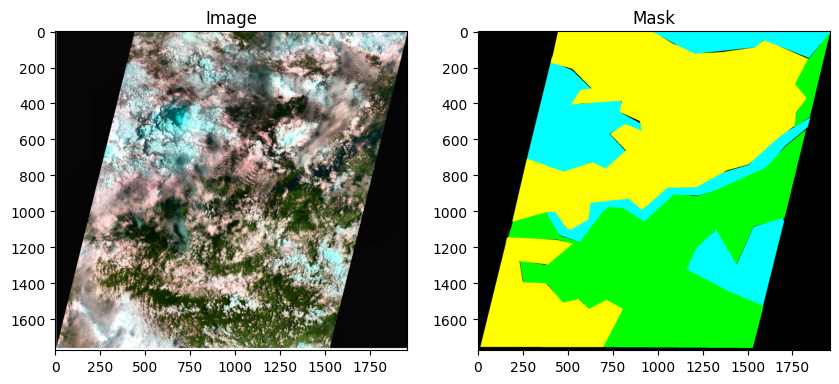

In [ ]:
sample = os.listdir(IMAGE_DIR)[0]

img = cv2.imread(os.path.join(IMAGE_DIR, sample))
mask = cv2.imread(os.path.join(MASK_DIR, sample), 0)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Image")

plt.subplot(1,2,2)
plt.imshow(color_mask(mask))
plt.title("Mask")

plt.show()

In [ ]:
import os
import cv2
import numpy as np

IMG_HEIGHT = 256
IMG_WIDTH = 256

image_dir = "/content/drive/MyDrive/LULC_Project/LULC train"
mask_dir  = "/content/drive/MyDrive/LULC_Project/masks"

images = []
masks = []

image_files = sorted(os.listdir(image_dir))
mask_files = sorted(os.listdir(mask_dir))

print("Images:", len(image_files))
print("Masks :", len(mask_files))

for img_file, mask_file in zip(image_files, mask_files):

    img_path = os.path.join(image_dir, img_file)
    mask_path = os.path.join(mask_dir, mask_file)

    img = cv2.imread(img_path)
    mask = cv2.imread(mask_path, 0)


    if img is None:
        print("Image not loaded:", img_path)
        continue

    if mask is None:
        print("Mask not loaded:", mask_path)
        continue

    # Resize
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
    mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)

    # Normalize image
    img = img / 255.0

    images.append(img)
    masks.append(mask)

# Convert to numpy
X = np.array(images)
Y = np.array(masks)

print("Final Shapes:")
print("X:", X.shape)
print("Y:", Y.shape)

Images: 154
Masks : 154
Final Shapes:
X: (154, 256, 256, 3)
Y: (154, 256, 256)


In [ ]:
from sklearn.model_selection import train_test_split

X_new_train, X_new_val, y_new_train, y_new_val = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

y_new_train = np.expand_dims(y_new_train, -1)
y_new_val   = np.expand_dims(y_new_val, -1)


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

IMG_HEIGHT = 256
IMG_WIDTH = 256
num_classes = 7

inputs = Input((IMG_HEIGHT, IMG_WIDTH, 3))

# Encoder
c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(inputs)
c1 = BatchNormalization()(c1)
c1 = Dropout(0.1)(c1)
c1 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
c1 = BatchNormalization()(c1)
p1 = MaxPooling2D((2, 2))(c1)

c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
c2 = BatchNormalization()(c2)
c2 = Dropout(0.1)(c2)
c2 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
c2 = BatchNormalization()(c2)
p2 = MaxPooling2D((2, 2))(c2)

c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
c3 = BatchNormalization()(c3)
c3 = Dropout(0.2)(c3)
c3 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
c3 = BatchNormalization()(c3)
p3 = MaxPooling2D((2, 2))(c3)

c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
c4 = BatchNormalization()(c4)
c4 = Dropout(0.2)(c4)
c4 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
c4 = BatchNormalization()(c4)
p4 = MaxPooling2D((2, 2))(c4)

# Bottleneck
c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p4)
c5 = BatchNormalization()(c5)
c5 = Dropout(0.3)(c5)
c5 = Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)
c5 = BatchNormalization()(c5)

# Decoder
u6 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c5)
u6 = concatenate([u6, c4])
c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u6)
c6 = BatchNormalization()(c6)
c6 = Dropout(0.2)(c6)
c6 = Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6)
c6 = BatchNormalization()(c6)

u7 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c6)
u7 = concatenate([u7, c3])
c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7)
c7 = BatchNormalization()(c7)
c7 = Dropout(0.2)(c7)
c7 = Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7)
c7 = BatchNormalization()(c7)

u8 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c7)
u8 = concatenate([u8, c2])
c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u8)
c8 = BatchNormalization()(c8)
c8 = Dropout(0.1)(c8)
c8 = Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8)
c8 = BatchNormalization()(c8)

u9 = Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c8)
u9 = concatenate([u9, c1], axis=3)
c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u9)
c9 = BatchNormalization()(c9)
c9 = Dropout(0.1)(c9)
c9 = Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9)
c9 = BatchNormalization()(c9)

# Output
outputs = Conv2D(num_classes, (1, 1), activation='softmax')(c9)

model = Model(inputs=[inputs], outputs=[outputs])

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ dropout[0][0]     │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ dropout_1[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ dropout_2[0][0] 

 Total params: 1,947,095 (7.43 MB)

 Trainable params: 1,944,151 (7.42 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [ ]:
# Ensure correct mask shape (IMPORTANT)
y_new_train = np.squeeze(y_new_train)
y_new_val   = np.squeeze(y_new_val)

y_new_train = np.expand_dims(y_new_train, axis=-1)
y_new_val   = np.expand_dims(y_new_val, axis=-1)

print("Train mask shape:", y_new_train.shape)

Train mask shape: (123, 256, 256, 1)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

batch_size = 8
seed = 42

# Image augmentation
image_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Mask generator (NO normalization)
mask_datagen = ImageDataGenerator()

# Image generator
image_generator = image_datagen.flow(
    X_new_train,
    batch_size=batch_size,
    seed=seed
)

# Mask generator
mask_generator = mask_datagen.flow(
    y_new_train,
    batch_size=batch_size,
    seed=seed
)

# Combine both
def combined_generator(img_gen, mask_gen):
    while True:
        img_batch = next(img_gen)
        mask_batch = next(mask_gen)

        yield img_batch, np.squeeze(mask_batch, axis=-1)

# FINAL generator
train_generator = combined_generator(image_generator, mask_generator)

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

IMG_HEIGHT = 256
IMG_WIDTH = 256
num_classes = 7   # IMPORTANT

inputs = Input((IMG_HEIGHT, IMG_WIDTH, 3))

vgg = VGG16(weights='imagenet', include_top=False, input_tensor=inputs)

# Freeze encoder
for layer in vgg.layers:
    layer.trainable = False

# Encoder outputs
c1 = vgg.get_layer("block1_conv2").output
c2 = vgg.get_layer("block2_conv2").output
c3 = vgg.get_layer("block3_conv3").output
c4 = vgg.get_layer("block4_conv3").output
c5 = vgg.get_layer("block5_conv3").output

# Decoder
u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
u6 = concatenate([u6, c4])
c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)

u7 = Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
u7 = concatenate([u7, c3])
c7 = Conv2D(256, 3, activation='relu', padding='same')(u7)
c7 = Conv2D(256, 3, activation='relu', padding='same')(c7)

u8 = Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
u8 = concatenate([u8, c2])
c8 = Conv2D(128, 3, activation='relu', padding='same')(u8)
c8 = Conv2D(128, 3, activation='relu', padding='same')(c8)

u9 = Conv2DTranspose(64, 2, strides=2, padding='same')(c8)
u9 = concatenate([u9, c1])
c9 = Conv2D(64, 3, activation='relu', padding='same')(u9)
c9 = Conv2D(64, 3, activation='relu', padding='same')(c9)

outputs = Conv2D(num_classes, (1,1), activation='softmax')(c9)

model_transfer = Model(inputs, outputs)

model_transfer.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_transfer.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 256, 256,  │      1,792 │ input_layer_1[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 256, 256,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 128, 128,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 128, 128,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 128, 128,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 64, 64,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 64, 64,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 64, 64,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 64, 64,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 32, 32,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 32, 32,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 32, 32,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 32, 32,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_pool         │ (None, 16, 16,    │          0 │ block4_conv3[0][… │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv1        │ (None, 16, 16,    │  2,359,808 │ block4_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv2        │ (None, 16, 16,    │  2,359,808 │ block5_conv1[0][

 Total params: 25,855,047 (98.63 MB)

 Trainable params: 11,140,359 (42.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

epochs_transfer = 50
batch_size = 16

steps_per_epoch = max(5, len(X_new_train) // batch_size)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    verbose=1,
    min_lr=1e-6
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("Steps per epoch:", steps_per_epoch)

history_transfer = model_transfer.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=epochs_transfer,
    validation_data=(X_new_val, y_new_val),
    callbacks=[lr_scheduler, early_stop],
    verbose=1
)

Steps per epoch: 7
Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.4136 - loss: 1.8597 - val_accuracy: 0.5288 - val_loss: 1.3677 - learning_rate: 0.0010
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 475ms/step - accuracy: 0.4948 - loss: 1.3242 - val_accuracy: 0.6151 - val_loss: 1.2571 - learning_rate: 0.0010
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 34s 6s/step - accuracy: 0.4965 - loss: 1.3867 - val_accuracy: 0.6253 - val_loss: 1.1930 - learning_rate: 0.0010
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 488ms/step - accuracy: 0.5442 - loss: 1.2210 - val_accuracy: 0.6200 - val_loss: 1.1855 - learning_rate: 0.0010
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 442ms/step - accuracy: 0.4844 - loss: 1.3228 - val_accuracy: 0.6109 - val_loss: 1.2122 - learning_rate: 0.0010
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 471ms/step - accuracy: 0.5256 - loss: 1.2723 - val_accuracy: 0.5912 - val_loss: 1.2140 - learning_rate: 0.0010
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 472ms/step - accuracy: 0.5263 - loss: 1.2380 -

In [ ]:
y_pred = model_transfer.predict(X_new_val)
y_pred = np.argmax(y_pred, axis=-1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [ ]:
y_true = np.squeeze(y_new_val)

In [ ]:

y_true_flat = y_true.flatten()
y_pred_flat = y_pred.flatten()

In [ ]:
mask = y_true_flat != 0  # ignore background

y_true_filtered = y_true_flat[mask]
y_pred_filtered = y_pred_flat[mask]

In [ ]:
from sklearn.metrics import accuracy_score

oa = accuracy_score(y_true_flat, y_pred_flat)
print("Overall Accuracy (OA):", round(oa*100, 2), "%")

Overall Accuracy (OA): 65.66 %


In [ ]:
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(y_true_flat, y_pred_flat)
print("Kappa Coefficient:", round(kappa, 4))

Kappa Coefficient: 0.4388


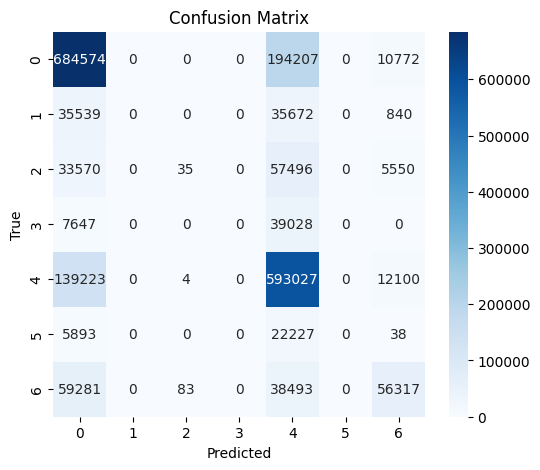

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true_flat, y_pred_flat)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()

In [ ]:
class_names = [ "Background",
    "Agriculture",  # 1
    "Barren",       # 2
    "Built-up",     # 3
    "Forest",       # 4
    "Grass",        # 5
    "Water"         # 6
]

<Axes: >

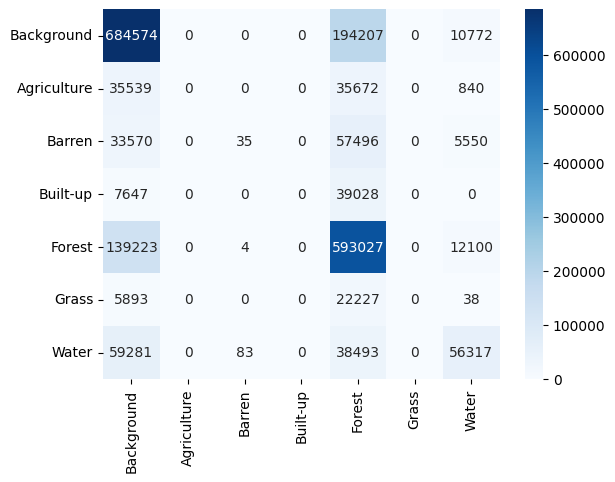

In [ ]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

In [ ]:
print("\nTraining Complete!")
print("Best Accuracy:", round(oa*100, 2), "%")


Training Complete!
Best Accuracy: 65.66 %


In [ ]:
y_pred = model_transfer.predict(X_new_val)

# Convert softmax → class labels
y_pred = np.argmax(y_pred, axis=-1)
y_true = np.squeeze(y_new_val)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 579ms/step


In [ ]:
from sklearn.metrics import mean_squared_error

mse_list = []
for i in range(len(y_true)):
    mse = mean_squared_error(
        y_true[i].flatten(),
        y_pred[i].flatten()
    )
    mse_list.append(mse)

mse_value = np.mean(mse_list)
print("MSE:", mse_value)

MSE: 4.512957173009073


In [ ]:
import math

def compute_psnr(mse):
    if mse == 0:
        return 100
    return 20 * math.log10(255.0 / math.sqrt(mse))

psnr_value = compute_psnr(mse_value)
print("PSNR:", psnr_value)

PSNR: 41.58619148689242


In [ ]:
from skimage.metrics import structural_similarity as ssim

ssim_list = []
for i in range(len(y_true)):
    s = ssim(y_true[i], y_pred[i], data_range=y_pred[i].max() - y_pred[i].min())
    ssim_list.append(s)

ssim_value = np.mean(ssim_list)
print("SSIM:", ssim_value)

SSIM: 0.5538200103164551


In [ ]:
# Take one test image
idx = 0   # change index to test different images

test_img = X_new_val[idx]

# Expand dims (important)
pred = model_transfer.predict(np.expand_dims(test_img, axis=0))

# Convert probabilities → class labels
pred_mask = np.argmax(pred, axis=-1)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
